## **Does Physical Activity Predict Income**

**Data:** CDC Behavioral Risk Factor Surveillance System (BRFSS) 2019, a custom extract with 418,268 respondents and 29 columns. Income is a household income bracket (8 brackets).


## **Needed Libraries**

In [277]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

## **Data Cleaning**

- **Columns dropped:** `BIRTHSEX` (84% missing), `EXEROFT2` and `EXERHMM2` (over 50% missing), `_AGEG5YR` (duplicates `_AGE80`), and the exercise-type codes `EXRACT11` and `EXRACT21`. `_RACE` was not used as a predictor.
- **Rows kept:** a valid income bracket (1 to 8), a yes/no answer on exercise, and complete activity data. This takes 418,268 respondents down to 307,297, and 82 more are removed for impossible activity totals (307,215 remain).
- **Survey codes:** refused and "don't know" answers become missing. For `CHILDREN` and `PHYSHLTH`, 88 means none and becomes 0.
- **Activity minutes:** people who report no exercise get 0 minutes. `PA2MIN_` counts vigorous minutes twice, so real minutes are `PA2MIN_` minus `PA2VIGM_`. Anything over a full week (10,080 minutes) is removed.
- **Other conversions:** BMI is divided by 100, and exercise frequency codes become times per week.
- **Missing values** that remain are handled by the models: Gradient Boosting accepts them directly and the Random Forest fills them with training-set medians.

In [278]:
# Read in data set and use SEQNO rather than Python built in row index
dataset = pd.read_csv("../raw_data/brfss_2019_custom.csv", index_col=0)
print(f"Dataset shape: {dataset.shape}")
print(f"Duplicates {dataset.duplicated().sum()}")
dataset.head()

Dataset shape: (418268, 29)
Duplicates 0


,BIRTHSEX,_RACE,_AGEG5YR,GENHLTH,INCOME2,EXERANY2,EXRACT11,EXRACT21,EXEROFT1,EXEROFT2,...,_URBSTAT,EDUCA,EMPLOY1,MARITAL,CHILDREN,PHYSHLTH,_BMI5,_PSU,_STSTR,_LLCPWT
SEQNO,,,,,,,,,,,,,,,,,,,,,
2019000001,NaN,2.0,13,3.0,3.0,2.0,NaN,NaN,NaN,NaN,...,1.0,3.0,7.0,2.0,88.0,15.0,2817.0,2019000001,11011,135.304080
2019000002,NaN,1.0,11,4.0,5.0,1.0,64.0,73.0,202.0,105.0,...,1.0,5.0,7.0,1.0,88.0,10.0,1854.0,2019000002,11012,1454.882220
2019000003,NaN,2.0,10,3.0,7.0,1.0,2.0,64.0,101.0,205.0,...,1.0,6.0,7.0,3.0,88.0,88.0,3162.0,2019000003,11011,215.576852
2019000004,NaN,1.0,13,4.0,6.0,NaN,NaN,NaN,NaN,NaN,...,1.0,5.0,7.0,3.0,88.0,30.0,2030.0,2019000004,11011,261.282838
2019000005,NaN,1.0,13,2.0,99.0,2.0,NaN,NaN,NaN,NaN,...,2.0,5.0,5.0,1.0,88.0,88.0,2148.0,2019000005,11011,535.270103


In [279]:
# Check the percengae of nulls for each colun to see what is useful 
for col in dataset.columns:
    null_percentage = round(dataset[col].isna().mean() * 100, 2)
    print(f"{col}: {null_percentage}% missing")

BIRTHSEX: 84.46% missing
_RACE: 0.0% missing
_AGEG5YR: 0.0% missing
GENHLTH: 0.01% missing
INCOME2: 1.65% missing
EXERANY2: 4.98% missing
EXRACT11: 31.17% missing
EXRACT21: 32.19% missing
EXEROFT1: 32.38% missing
EXEROFT2: 55.97% missing
EXERHMM1: 32.53% missing
EXERHMM2: 56.05% missing
STRENGTH: 6.47% missing
PA2MIN_: 33.56% missing
PA2VIGM_: 32.91% missing
PAMISS2_: 0.0% missing
_AGE80: 0.0% missing
SEXVAR: 0.0% missing
_STATE: 0.0% missing
_URBSTAT: 2.02% missing
EDUCA: 0.01% missing
EMPLOY1: 0.68% missing
MARITAL: 0.01% missing
CHILDREN: 1.13% missing
PHYSHLTH: 0.01% missing
_BMI5: 8.66% missing
_PSU: 0.0% missing
_STSTR: 0.0% missing
_LLCPWT: 0.0% missing


In [280]:
# Create a copy of the original dataset
cleaned_dataset = dataset.copy()
# Keep track of how many records we started with
before = len(cleaned_dataset)

# Drop redundant columns & dropped high NULL count of over 50% 
drop_cols = ["BIRTHSEX", "_RACE", "_AGEG5YR", "EXEROFT2", "EXERHMM2"]
cleaned_dataset = cleaned_dataset.drop(columns=drop_cols, errors="ignore")

# Keep respondents with a valid income bracket (1-8) and answered yes or no to excersise
cleaned_dataset = cleaned_dataset[cleaned_dataset["INCOME2"].isin(range(1, 9))].copy()
cleaned_dataset = cleaned_dataset[cleaned_dataset["EXERANY2"].isin([1, 2])].copy()

# Keep respondents with complete physical activity information
# 0 = complete, 1 = missing, 9 = unknown/refused
cleaned_dataset = cleaned_dataset[cleaned_dataset["PAMISS2_"] < 0.5].copy()

# People who report no exercise have zero weekly activity minutes.
cleaned_dataset.loc[cleaned_dataset["EXERANY2"] == 2,["PA2MIN_", "PA2VIGM_"]] = 0

# Remove remaining records with missing activity minutes.
cleaned_dataset = cleaned_dataset.dropna(subset=["PA2MIN_"])

# See how this block effected the row count 
after = len(cleaned_dataset)
print(f"Original row count: {before}")
print(f"Remaining row count: {after}")
print(f"Removed rows: {before - after}")
cleaned_dataset.head()

Original row count: 418268
Remaining row count: 307297
Removed rows: 110971


,GENHLTH,INCOME2,EXERANY2,EXRACT11,EXRACT21,EXEROFT1,EXERHMM1,STRENGTH,PA2MIN_,PA2VIGM_,...,_URBSTAT,EDUCA,EMPLOY1,MARITAL,CHILDREN,PHYSHLTH,_BMI5,_PSU,_STSTR,_LLCPWT
SEQNO,,,,,,,,,,,,,,,,,,,,,
2019000001,3.0,3.0,2.0,NaN,NaN,NaN,NaN,210.0,0.0,0.000000e+00,...,1.0,3.0,7.0,2.0,88.0,15.0,2817.0,2019000001,11011,135.304080
2019000002,4.0,5.0,1.0,64.0,73.0,202.0,100.0,888.0,778.0,5.397605e-79,...,1.0,5.0,7.0,1.0,88.0,10.0,1854.0,2019000002,11012,1454.882220
2019000003,3.0,7.0,1.0,2.0,64.0,101.0,100.0,102.0,190.0,6.000000e+01,...,1.0,6.0,7.0,3.0,88.0,88.0,3162.0,2019000003,11011,215.576852
2019000007,2.0,7.0,1.0,98.0,73.0,102.0,45.0,103.0,270.0,9.000000e+01,...,2.0,6.0,7.0,2.0,88.0,30.0,3298.0,2019000007,11011,282.923012
2019000009,3.0,5.0,1.0,64.0,88.0,102.0,30.0,888.0,120.0,6.000000e+01,...,1.0,4.0,7.0,3.0,88.0,15.0,2399.0,2019000009,11011,316.081502


In [281]:
print(cleaned_dataset['EXRACT11'].unique())
print(cleaned_dataset['EXRACT21'].unique())

[nan 64.  2. 98.  7.  6. 67. 54. 34. 69. 18. 37. 14. 11. 73. 19. 15. 58.
 20.  1. 72. 76.  5. 60. 25. 61. 22. 57. 36. 66. 40.  9. 31. 13. 24. 51.
 28. 38. 71. 52. 12. 63. 68. 75. 16.  8. 74. 43.  4. 55. 26. 23. 49. 48.
 50. 44. 33. 39. 10. 42. 41. 35. 59. 32. 46. 62. 17. 56. 30. 29. 27. 21.
 53. 45.  3. 47.]
[nan 73. 64. 88. 18.  7. 28. 98. 69. 76. 67.  5. 20.  2.  6. 14. 37. 11.
  9. 36. 54. 13. 34. 40. 31. 60. 16. 57. 75. 58. 71. 68. 19. 15. 52. 26.
 61. 22. 72. 12. 25. 24. 35. 23.  3. 74. 10. 63. 44.  8. 66. 56. 43. 38.
 51. 30. 49. 48. 47. 50. 32. 42. 33.  1. 27. 39. 17. 59. 53. 62. 41. 55.
  4. 21. 29. 46. 45.]


In [282]:
# Remove exercise-type columns numbers coded did not match legend and columns calculated on 
cleaned_dataset = cleaned_dataset.drop(columns=["EXRACT11", "EXRACT21"], errors="ignore")

# Unknown and refused survey responses become Nan
cleaned_dataset["GENHLTH"] = cleaned_dataset["GENHLTH"].replace({7: np.nan, 9: np.nan})

cleaned_dataset["EDUCA"] = cleaned_dataset["EDUCA"].replace(9, np.nan)

cleaned_dataset["EMPLOY1"] = cleaned_dataset["EMPLOY1"].replace(9, np.nan)

cleaned_dataset["CHILDREN"] = cleaned_dataset["CHILDREN"].replace({88: 0, 99: np.nan})

cleaned_dataset["PHYSHLTH"] = cleaned_dataset["PHYSHLTH"].replace({88: 0, 77: np.nan, 99: np.nan})

cleaned_dataset["EXERHMM1"] = cleaned_dataset["EXERHMM1"].replace({777: np.nan, 999: np.nan})

cleaned_dataset["MARITAL"] = cleaned_dataset["MARITAL"].replace(9, np.nan)

# Convert BMI to its actual units.
cleaned_dataset["_BMI5"] = cleaned_dataset["_BMI5"] / 100

In [283]:
def clean_strength(value):
    # Never exercises.
    if value == 888:
        return 0
    # Weekly code: 103 means 3 times per week.
    elif 101 <= value <= 199:
        return value - 100
    # Monthly code: 212 means 12 times per month.
    elif 201 <= value <= 299:
        return (value - 200) / 4.345
    # Unknown, refused, blank, or invalid response.
    else:
        return float("nan")

# Convert strength-training frequency and excersise frequency to times per week   
cleaned_dataset["STRENGTH_WEEKLY"] = (cleaned_dataset["STRENGTH"].apply(clean_strength))
cleaned_dataset["EXEROFT1_CLEAN"] = (cleaned_dataset["EXEROFT1"].apply(clean_strength))

# Convert hours/minutes into total minutes.
exercise_time = cleaned_dataset["EXERHMM1"]
# Valid minute values must be 0-59.
valid_time = (exercise_time.notna() & (exercise_time % 100 < 60) & (exercise_time >= 1) & (exercise_time <= 959))

# Create a new row and fill it with NAN before calculation
cleaned_dataset["EXERHMM1_MINUTES"] = np.nan
cleaned_dataset.loc[valid_time, "EXERHMM1_MINUTES"] = ((exercise_time[valid_time] // 100) * 60 + (exercise_time[valid_time] % 100))

# Respondents who do not exercise have zero frequency and duration.
cleaned_dataset.loc[cleaned_dataset["EXERANY2"] == 2, ["EXEROFT1_CLEAN", "EXERHMM1_MINUTES"]] = 0

In [284]:
# Print max and min for each col to look for outliers
for col in cleaned_dataset.columns:
    print(f"Max for {col}: {cleaned_dataset[col].max()}")
    print(f"Min for {col}: {cleaned_dataset[col].min()}")
    print()

Max for GENHLTH: 5.0
Min for GENHLTH: 1.0

Max for INCOME2: 8.0
Min for INCOME2: 1.0

Max for EXERANY2: 2.0
Min for EXERANY2: 1.0

Max for EXEROFT1: 999.0
Min for EXEROFT1: 101.0

Max for EXERHMM1: 959.0
Min for EXERHMM1: 1.0

Max for STRENGTH: 999.0
Min for STRENGTH: 101.0

Max for PA2MIN_: 96000.0
Min for PA2MIN_: 0.0

Max for PA2VIGM_: 48000.0
Min for PA2VIGM_: 0.0

Max for PAMISS2_: 5.39760534693403e-79
Min for PAMISS2_: 5.39760534693403e-79

Max for _AGE80: 80
Min for _AGE80: 18

Max for SEXVAR: 2
Min for SEXVAR: 1

Max for _STATE: 72
Min for _STATE: 1

Max for _URBSTAT: 2.0
Min for _URBSTAT: 1.0

Max for EDUCA: 6.0
Min for EDUCA: 1.0

Max for EMPLOY1: 8.0
Min for EMPLOY1: 1.0

Max for MARITAL: 6.0
Min for MARITAL: 1.0

Max for CHILDREN: 25.0
Min for CHILDREN: 0.0

Max for PHYSHLTH: 30.0
Min for PHYSHLTH: 0.0

Max for _BMI5: 98.7
Min for _BMI5: 12.0

Max for _PSU: 2019017419
Min for _PSU: 2019000001

Max for _STSTR: 722019
Min for _STSTR: 11011

Max for _LLCPWT: 42066.7308870863
M

In [285]:
# Convert extremely small zero values to exactly zero.
for col in ["PA2MIN_", "PA2VIGM_"]:
    cleaned_dataset.loc[cleaned_dataset[col].abs() < 0.000001, col] = 0

# Estimate actual exercise duration, PA2MIN_ includes vigorous activity twice.
cleaned_dataset["ACTIVITY_MINUTES"] = (cleaned_dataset["PA2MIN_"] - cleaned_dataset["PA2VIGM_"])

# Remove negative durations and durations longer than a week
invalid_activity = ((cleaned_dataset["ACTIVITY_MINUTES"] < 0) 
    | (cleaned_dataset["ACTIVITY_MINUTES"] > 10080)
    | (cleaned_dataset["PA2VIGM_"] < 0)
    | (cleaned_dataset["PA2VIGM_"] > 10080))

print("Rows flagged:", invalid_activity.sum())

# Remove only invalid duration records
cleaned_dataset = cleaned_dataset[invalid_activity == False].copy()
print("Rows after activity checks:", len(cleaned_dataset))
# Count missing values in weekly activity minutes.
print("Missing weekly minutes:", cleaned_dataset["PA2MIN_"].isna().sum())

Rows flagged: 82
Rows after activity checks: 307215
Missing weekly minutes: 0


In [286]:
# Final descriptive checks (do not change the dataset).
print("Remaining missing values:")
print(cleaned_dataset.isna().sum().sort_values(ascending=False))

print("\nIncome counts:")
print(cleaned_dataset["INCOME2"].value_counts().sort_index())

print("\nActivity/health outliers flagged for inspection (not removed):")
print("BMI > 50:", (cleaned_dataset["_BMI5"] > 50).sum())
print("Strength sessions > 30/week:", (cleaned_dataset["STRENGTH_WEEKLY"] > 30).sum())
print("Exercise sessions > 30/week:", (cleaned_dataset["EXEROFT1_CLEAN"] > 30).sum())
print(cleaned_dataset[["PA2MIN_", "PA2VIGM_", "ACTIVITY_MINUTES", "_BMI5"]].describe(percentiles=[.95, .99]))

Remaining missing values:
EXERHMM1            86338
EXEROFT1            86300
_BMI5               12514
_URBSTAT             6688
STRENGTH_WEEKLY      6005
PHYSHLTH             5574
STRENGTH             1382
CHILDREN             1266
EMPLOY1              1159
MARITAL               982
GENHLTH               477
EDUCA                 372
EXEROFT1_CLEAN        141
EXERHMM1_MINUTES      100
_STATE                  0
INCOME2                 0
SEXVAR                  0
_AGE80                  0
PAMISS2_                0
PA2VIGM_                0
PA2MIN_                 0
_PSU                    0
_STSTR                  0
_LLCPWT                 0
EXERANY2                0
ACTIVITY_MINUTES        0
dtype: int64

Income counts:
INCOME2
1.0     14021
2.0     14398
3.0     20870
4.0     26851
5.0     30913
6.0     42206
7.0     49570
8.0    108386
Name: count, dtype: int64

Activity/health outliers flagged for inspection (not removed):
BMI > 50: 2540
Strength sessions > 30/week: 193
Exercise se

## **Statistical & Exploratory Analysis** 

In [287]:
# Use the finished cleaned data for the graphs.
data_graph = cleaned_dataset.copy()

# Labels used in income graphs.
income_labels = ["<$10k", "$10-15k", "$15-20k", "$20-25k",
                 "$25-35k", "$35-50k", "$50-75k", "$75k+"]

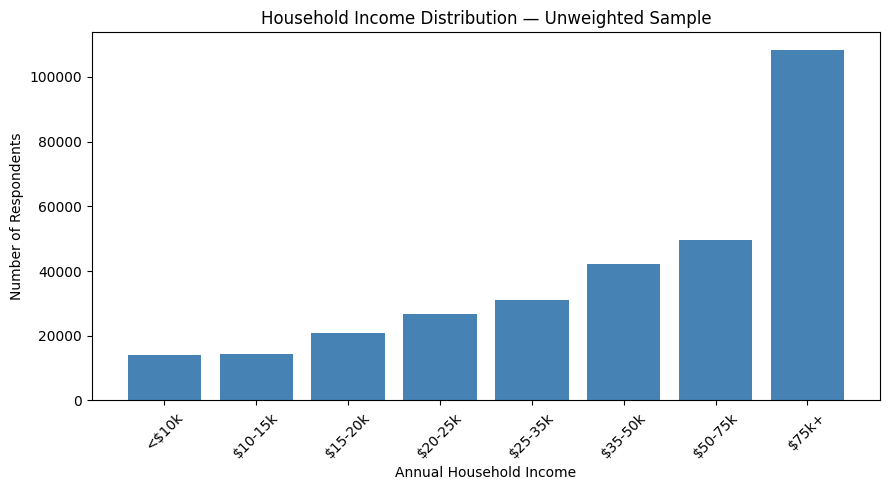

In [288]:
# Count respondents in each income category.
income_counts = (data_graph["INCOME2"].value_counts().reindex(range(1, 9), fill_value=0))

plt.figure(figsize=(9, 5))
plt.bar(income_labels, income_counts.values, color="steelblue")

plt.title("Household Income Distribution — Unweighted Sample")
plt.xlabel("Annual Household Income")
plt.ylabel("Number of Respondents")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

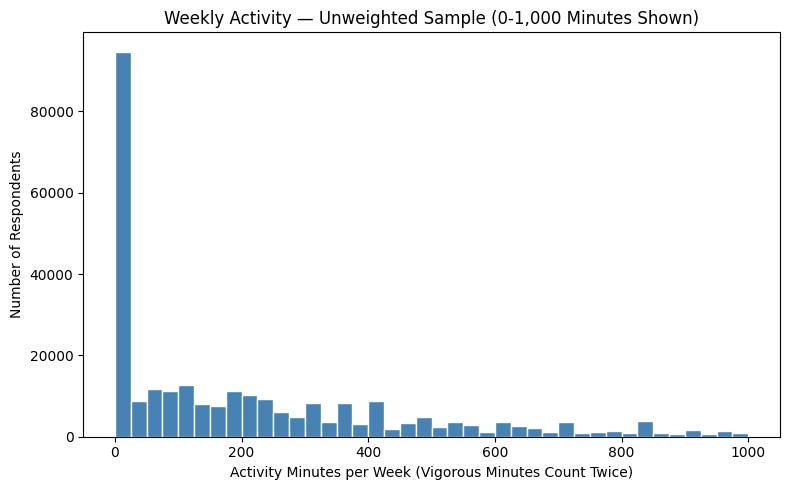

In [289]:
# Display activity from 0 to 1000 minutes to make the
# main distribution easier to see without extreme values.
plt.figure(figsize=(8, 5))

plt.hist(data_graph["PA2MIN_"],bins=40,range=(0, 1000),color="steelblue",edgecolor="white")

plt.title("Weekly Activity — Unweighted Sample (0-1,000 Minutes Shown)")
plt.xlabel("Activity Minutes per Week (Vigorous Minutes Count Twice)")
plt.ylabel("Number of Respondents")
plt.tight_layout()
plt.show()

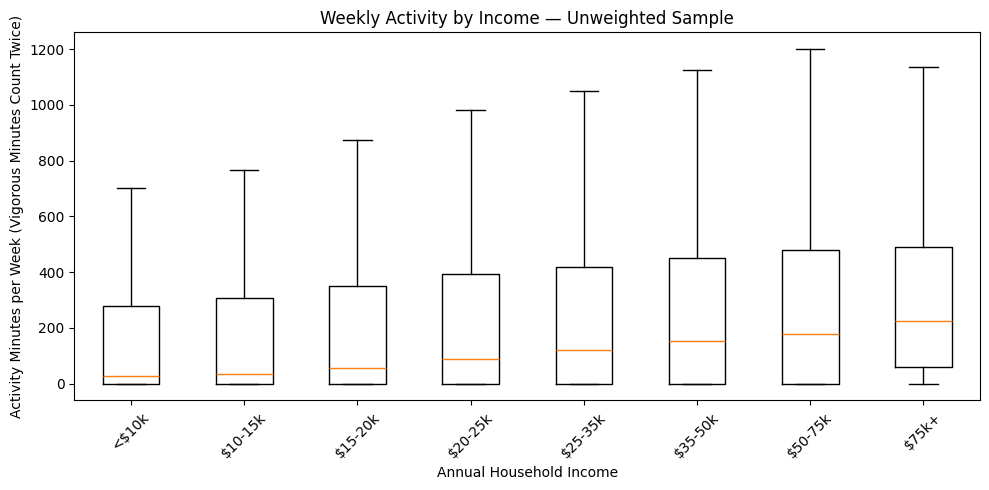

In [290]:
# Collect activity minutes for each income category.
# Shows higher median average as income increases
activity_groups = []

for income in range(1, 9):
    minutes = data_graph.loc[data_graph["INCOME2"] == income, "PA2MIN_"].dropna()

    activity_groups.append(minutes.to_numpy())

# Create one box for each income category.
plt.figure(figsize=(10, 5))

# Hide extreme points for readability, but keep all values when calculating the boxplots.
plt.boxplot(activity_groups, showfliers=False)

plt.title("Weekly Activity by Income — Unweighted Sample")
plt.xlabel("Annual Household Income")
plt.ylabel("Activity Minutes per Week (Vigorous Minutes Count Twice)")
plt.xticks(range(1, 9), income_labels, rotation=45)

plt.tight_layout()
plt.show()

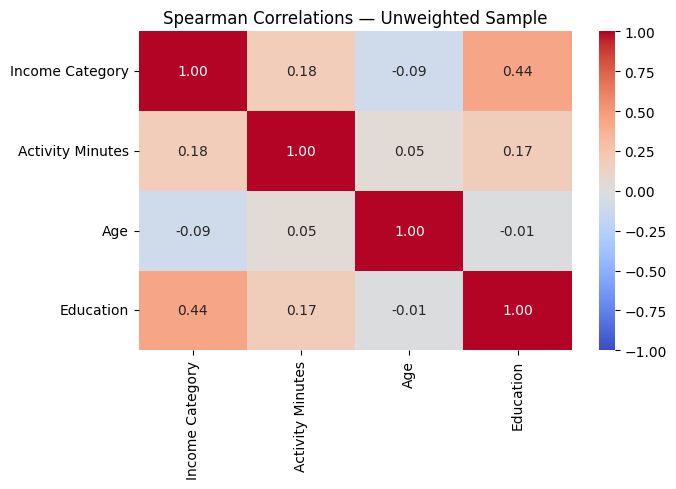

In [291]:
# Select columns for the heatmap.
correlation_data = data_graph[["INCOME2", "PA2MIN_", "_AGE80", "EDUCA"]].copy()

# Keep valid education responses; mark other responses as missing.
correlation_data["EDUCA"] = correlation_data["EDUCA"].where(correlation_data["EDUCA"].isin(range(1, 7)))

# Give columns readable names.
correlation_data.columns = ["Income Category", "Activity Minutes", "Age", "Education"]

plt.figure(figsize=(7, 5))

sns.heatmap(correlation_data.corr(method="spearman"),annot=True,cmap="coolwarm",vmin=-1,vmax=1,fmt=".2f")

plt.title("Spearman Correlations — Unweighted Sample")
plt.tight_layout()
plt.show()

In [292]:
# Compare activity levels across income groups
activity_summary = data_graph.groupby("INCOME2")["PA2MIN_"].agg(["count", "median", "mean"])
activity_summary.index = income_labels
print(activity_summary.round(2))

          count  median    mean
<$10k     14021    28.0  304.64
$10-15k   14398    35.0  322.45
$15-20k   20870    56.0  342.83
$20-25k   26851    90.0  373.95
$25-35k   30913   120.0  411.37
$35-50k   42206   154.0  432.51
$50-75k   49570   180.0  433.05
$75k+    108386   225.0  425.63


### **What the exploratory charts show**

- Income is skewed toward the top: 35% of respondents are in the $75k+ bracket.
- Median weekly activity climbs steadily with income, from 28 minutes in the lowest bracket to 225 minutes in the highest.
- Average activity levels off above $35k at about 430 minutes. The lowest brackets have a much higher average than median (305 vs. 28), which suggests many people with little or no activity alongside a few with very high totals.
- Education is a much stronger partner of income than activity in the correlation heatmap (roughly 0.44 vs. 0.18 on the same data).

## **Mining Technique (Classification)**

Goal: predict household income bracket from activity, demographics, and health, and test whether the activity columns add anything beyond the other predictors.

Models: Gradient Boosting (main model) and Random Forest (comparison). Targets: 8 brackets, 3 brackets, and yes/no splits at $50k and $75k.

In [293]:
# Keep the 8-category response and create the 3-category and binary targets
income_mapping = {1:1, 2:1, 3:1, 4:1, 5:2, 6:2, 7:2, 8:3}
cleaned_dataset["INCOME3"] = (cleaned_dataset["INCOME2"].map(income_mapping))

# Create two new income targets (0 = No, 1 = Yes)
cleaned_dataset["INCOME_50K"] = (cleaned_dataset["INCOME2"] >= 7).astype(int)
cleaned_dataset["INCOME_75K"] = (cleaned_dataset["INCOME2"] == 8).astype(int)

demographic_features = ["_AGE80", "SEXVAR", "_STATE", "_URBSTAT", "EDUCA", "EMPLOY1", "MARITAL", "CHILDREN"]

activity_features = ["EXERANY2", "PA2MIN_", "PA2VIGM_", "EXEROFT1_CLEAN", "STRENGTH_WEEKLY"]

health_features = ["GENHLTH", "PHYSHLTH", "_BMI5"]

demo_activity_features = demographic_features + activity_features
all_features = demo_activity_features + health_features

# Survey codes that represent categories rather than continuous measurements
cat_cols = ["_STATE", "_URBSTAT", "EDUCA", "EMPLOY1", "MARITAL", "SEXVAR", "EXERANY2"]
print(cleaned_dataset[["INCOME3", "INCOME_50K", "INCOME_75K"]].apply(pd.Series.value_counts))

    INCOME3  INCOME_50K  INCOME_75K
0       NaN    149259.0    198829.0
1   76140.0    157956.0    108386.0
2  122689.0         NaN         NaN
3  108386.0         NaN         NaN


### **Train, validation, and test split**

The respondents are split 60% training, 20% validation, and 20% test, keeping the income brackets in the same proportions in each part. Models are fit on training rows and compared on validation rows. The test rows are held back until the final model. Rows are split by position because SEQNO repeats across states.

In [294]:
# Create row positions SEQID Duplicate are differentiated by state code 
rows = np.arange(len(cleaned_dataset))

# Reserve 20% for testing
train_rows, test_rows = train_test_split(rows, test_size=0.20, stratify=cleaned_dataset["INCOME2"], random_state=42)

# Split remaining 80% into training and validation
train_rows, val_rows = train_test_split(train_rows, test_size=0.25, stratify=cleaned_dataset["INCOME2"].iloc[train_rows], random_state=42)

# 60% train 20% test 20% validation
print("Train:", len(train_rows))
print("Validation:", len(val_rows))
print("Test:", len(test_rows))

Train: 184329
Validation: 61443
Test: 61443


In [295]:
# Select predictors and the 3-bracket income target.
X = cleaned_dataset[all_features].copy()
y = cleaned_dataset["INCOME3"]

# Treat survey categories as categories, not continuous numbers.
for col in cat_cols:
    X[col] = X[col].astype("Int64").astype("category")

# Select the training and validation respondents.
X_train = X.iloc[train_rows]
X_val = X.iloc[val_rows]
y_train = y.iloc[train_rows]
y_val = y.iloc[val_rows]

# Train Gradient Boosting.
gb_model = HistGradientBoostingClassifier(
    learning_rate=0.05,       # How much each new tree contributes
    max_iter=400,             # Maximum number of boosting rounds
    max_leaf_nodes=31,        # Maximum leaf nodes per tree
    min_samples_leaf=30,      # Minimum observations in each leaf
    l2_regularization=0.5,    # Helps prevent overfitting
    categorical_features="from_dtype",  # Automatically recognize categories
    early_stopping=True,      # Stop training when improvement levels off
    random_state=42           # Keep results reproducible
)
gb_model.fit(X_train, y_train)

# Evaluate using validation data.
gb_pred = gb_model.predict(X_val)
print("Gradient Boosting accuracy:", round(accuracy_score(y_val, gb_pred), 4))
print("Gradient Boosting macro F1:", round(f1_score(y_val, gb_pred, average="macro"), 4))
print(classification_report(y_val, gb_pred, zero_division=0))

Gradient Boosting accuracy: 0.6323
Gradient Boosting macro F1: 0.6358
              precision    recall  f1-score   support

           1       0.69      0.59      0.64     15228
           2       0.56      0.62      0.59     24538
           3       0.69      0.67      0.68     21677

    accuracy                           0.63     61443
   macro avg       0.65      0.63      0.64     61443
weighted avg       0.64      0.63      0.63     61443



In [296]:
# Prepare numeric inputs for Random Forest.
X_rf = cleaned_dataset[all_features].copy()
y_rf = cleaned_dataset["INCOME3"]

# Separate categorical and numeric columns.
cat_cols = [col for col in cat_cols if col in X_rf.columns]
num_cols = [col for col in X_rf.columns if col not in cat_cols]

X_rf_train = X_rf.iloc[train_rows].copy()
X_rf_val = X_rf.iloc[val_rows].copy()

# Fill missing values using only the training data.
for col in cat_cols:
    X_rf_train[col] = X_rf_train[col].fillna(-1)
    X_rf_val[col] = X_rf_val[col].fillna(-1)

# Fill data with medians
medians = X_rf_train[num_cols].median()
X_rf_train[num_cols] = X_rf_train[num_cols].fillna(medians)
X_rf_val[num_cols] = X_rf_val[num_cols].fillna(medians)

# Create numeric dummy columns and keep both datasets aligned.
X_rf_train = pd.get_dummies(X_rf_train, columns=cat_cols, dtype=int)
X_rf_val = pd.get_dummies(X_rf_val, columns=cat_cols, dtype=int)
X_rf_val = X_rf_val.reindex(columns=X_rf_train.columns, fill_value=0)

# Train and evaluate Random Forest.
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=50,
    class_weight="balanced",
    max_features=0.5,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_rf_train, y_rf.iloc[train_rows])
rf_pred = rf_model.predict(X_rf_val)
print("Random Forest accuracy:", round(accuracy_score(y_rf.iloc[val_rows], rf_pred), 4))
print("Random Forest macro F1:", round(f1_score(y_rf.iloc[val_rows], rf_pred, average="macro"), 4))
print(classification_report(y_rf.iloc[val_rows], rf_pred, zero_division=0))


Random Forest accuracy: 0.6118
Random Forest macro F1: 0.6145
              precision    recall  f1-score   support

           1       0.59      0.73      0.65     15228
           2       0.58      0.46      0.51     24538
           3       0.66      0.70      0.68     21677

    accuracy                           0.61     61443
   macro avg       0.61      0.63      0.61     61443
weighted avg       0.61      0.61      0.61     61443



### **Why yes/no income targets**

Predicting the exact bracket is hard because neighboring brackets look almost the same to the model. On three brackets, Gradient Boosting reached 63.2% accuracy and the Random Forest 61.2%, against about 40% for always guessing the largest group. The yes/no versions give the model one clear question to answer.

**How to read the table below.** Accuracy is compared with the Baseline column, which is the score from always guessing the larger group. ROC-AUC runs from 0.5 (a coin flip) to 1.0 (perfect) and measures how well the model ranks households above the income line ahead of households below it. All scores here are on the validation rows.

In [297]:
# Choose which predictor groups to compare.
experiments = [
    ("50k - Demographics", "INCOME_50K", demographic_features),
    ("50k - Activity", "INCOME_50K", activity_features),
    ("50k - Demographics + Activity", "INCOME_50K", demo_activity_features),
    ("50k - Demographics + Health", "INCOME_50K", demographic_features + health_features),
    ("50k - All Features", "INCOME_50K", all_features),
    ("75k - All Features", "INCOME_75K", all_features)
]

results = []

for name, target, features in experiments:
    # Select the predictors and the income target for this experiment.
    X = cleaned_dataset[features].copy()
    y = cleaned_dataset[target]

    # Convert only the categorical columns included in this experiment.
    for col in cat_cols:
        if col in X.columns:
            X[col] = X[col].astype("Int64").astype("category")

    # Use the same training and validation rows each time.
    X_train = X.iloc[train_rows]
    X_val = X.iloc[val_rows]
    y_train = y.iloc[train_rows]
    y_val = y.iloc[val_rows]

    # Train a new binary Gradient Boosting model.
    binary_model = HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=400,
        max_leaf_nodes=31,
        min_samples_leaf=30,
        l2_regularization=0.5,
        categorical_features="from_dtype",
        early_stopping=True,
        random_state=42
    )
    binary_model.fit(X_train, y_train)

    # Make predictions and calculate the validation scores.
    predictions = binary_model.predict(X_val)
    probabilities = binary_model.predict_proba(X_val)[:, 1]
    accuracy = accuracy_score(y_val, predictions)
    macro_f1 = f1_score(y_val, predictions, average="macro")
    auc = roc_auc_score(y_val, probabilities)
    baseline = y_val.value_counts(normalize=True).max()

    # Save one row of results per experiment.
    results.append([name, accuracy, macro_f1, auc, baseline])

# Show all experiments together.
comparison = pd.DataFrame(
    results, columns=["Model", "Accuracy", "Macro F1", "ROC-AUC", "Baseline"]
)
print(comparison.round(4).to_string(index=False))


                        Model  Accuracy  Macro F1  ROC-AUC  Baseline
           50k - Demographics    0.7671    0.7667   0.8503    0.5142
               50k - Activity    0.6177    0.6145   0.6496    0.5142
50k - Demographics + Activity    0.7697    0.7693   0.8542    0.5142
  50k - Demographics + Health    0.7735    0.7732   0.8573    0.5142
           50k - All Features    0.7749    0.7746   0.8596    0.5142
           75k - All Features    0.7794    0.7519   0.8485    0.6472


## **Does Activity Add Anything?**

The earlier table shows activity alone predicts income a little. The real question is whether it adds anything once other information is known. For each comparison below, one model uses a base set of features and a second model uses the same features plus the five activity columns. Both use the same settings, the same training rows, and the same validation rows. The score is the gain in ROC-AUC when activity is added. The test rows are not touched here.

In [298]:
# Compare income predictions with and without physical activity
age_sex_features = ["_AGE80", "SEXVAR"]

def compare_activity(name, features, train_rows, val_rows):

    # Prepare the original features
    X = cleaned_dataset[features].copy()

    # Prepare the same features plus physical activity
    X_activity = cleaned_dataset[features + activity_features].copy()

    # Convert categorical columns
    for col in cat_cols:
        if col in X.columns:
            X[col] = X[col].astype("Int64").astype("category")

        if col in X_activity.columns:
            X_activity[col] = X_activity[col].astype("Int64").astype("category")

    # Select our income target
    y = cleaned_dataset["INCOME_50K"]

    # Create two models with the same settings
    model1 = HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=400,
        max_leaf_nodes=31,
        min_samples_leaf=30,
        l2_regularization=0.5,
        categorical_features="from_dtype",
        early_stopping=True,
        random_state=42
    )

    model2 = HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=400,
        max_leaf_nodes=31,
        min_samples_leaf=30,
        l2_regularization=0.5,
        categorical_features="from_dtype",
        early_stopping=True,
        random_state=42
    )

    # Train both models
    model1.fit(X.iloc[train_rows], y.iloc[train_rows])
    model2.fit(X_activity.iloc[train_rows], y.iloc[train_rows])

    # Get predicted probabilities
    prob1 = model1.predict_proba(X.iloc[val_rows])[:, 1]
    prob2 = model2.predict_proba(X_activity.iloc[val_rows])[:, 1]

    # Get the correct income answers
    actual = y.iloc[val_rows]

    # Calculate ROC-AUC for each model
    auc1 = roc_auc_score(actual, prob1)
    auc2 = roc_auc_score(actual, prob2)

    return {
        "Comparison": name,
        "Without Activity": auc1,
        "With Activity": auc2,
        "Improvement": auc2 - auc1
    }

In [299]:
# Compare different feature groups
results = []

# Age and sex only
results.append(compare_activity("Age + Sex", age_sex_features, train_rows, val_rows))

# All demographic features
results.append(compare_activity("Demographics", demographic_features, train_rows, val_rows))

# Demographics and health
results.append(compare_activity("Demographics + Health",demographic_features + health_features,train_rows, val_rows))

# Under 65 respondents
ages = cleaned_dataset["_AGE80"].to_numpy()

train_young = train_rows[ages[train_rows] < 65]
val_young = val_rows[ages[val_rows] < 65]

results.append(compare_activity("Under 65", demographic_features + health_features, train_young, val_young))

# Display results
results_df = pd.DataFrame(results)

print(results_df.round(4))

              Comparison  Without Activity  With Activity  Improvement
0              Age + Sex            0.6197         0.6928       0.0730
1           Demographics            0.8503         0.8542       0.0038
2  Demographics + Health            0.8573         0.8596       0.0024
3               Under 65            0.8615         0.8637       0.0022


In [300]:
# Compare the effect of physical activity across age groups
age_groups = [(18, 34), (35, 49), (50, 64), (65, 80)]

age_results = []

for min_age, max_age in age_groups:
    # Select respondents in the current age group
    train_group = train_rows[(ages[train_rows] >= min_age) & (ages[train_rows] <= max_age)]

    val_group = val_rows[(ages[val_rows] >= min_age) & (ages[val_rows] <= max_age)]

    # Train both models and compare their results
    result = compare_activity(f"Ages {min_age}-{max_age}",
                            demographic_features + health_features,
                            train_group, val_group)

    age_results.append(result)

# Display age-group comparisons
age_results_df = pd.DataFrame(age_results)

print(age_results_df.round(4))

   Comparison  Without Activity  With Activity  Improvement
0  Ages 18-34            0.7915         0.7931       0.0017
1  Ages 35-49            0.8667         0.8698       0.0031
2  Ages 50-64            0.8777         0.8789       0.0011
3  Ages 65-80            0.8375         0.8398       0.0022


### What this shows

| Base features | AUC without activity | AUC with activity | Gain |
|---|---|---|---|
| Age + Sex | 0.6197 | 0.6928 | +0.0730 |
| Demographics | 0.8503 | 0.8542 | +0.0038 |
| Demographics + Health | 0.8573 | 0.8596 | +0.0024 |
| Under 65, Demographics + Health | 0.8615 | 0.8637 | +0.0022 |

By age group (Demographics + Health base): ages 18-34 gain +0.0017, ages 35-49 gain +0.0031, ages 50-64 gain +0.0011, ages 65-80 gain +0.0022.

- **Activity is informative when little else is known.** With only age and sex, adding activity raises AUC by about 0.073. Active people are more likely to be in higher-income households.
- **That signal mostly disappears once education, employment, and marital status are known.** Activity probably overlaps with those variables, so the model gets almost the same information without it.
- **The remaining gain is small.** A change of about 0.002 on a model that scores about 0.86 would not noticeably change who is classified correctly. Gains this small can move from run to run, so treat differences between individual age groups with caution.
- **Retirees are not driving the result.** The under-65 comparison matches the all-ages comparison.

## **Proper Model & Evaluation**

Final test accuracy: 0.7733
Final test macro F1: 0.7729
              precision    recall  f1-score   support

           0       0.77      0.76      0.76     29852
           1       0.77      0.79      0.78     31591

    accuracy                           0.77     61443
   macro avg       0.77      0.77      0.77     61443
weighted avg       0.77      0.77      0.77     61443

Final ROC-AUC: 0.8575


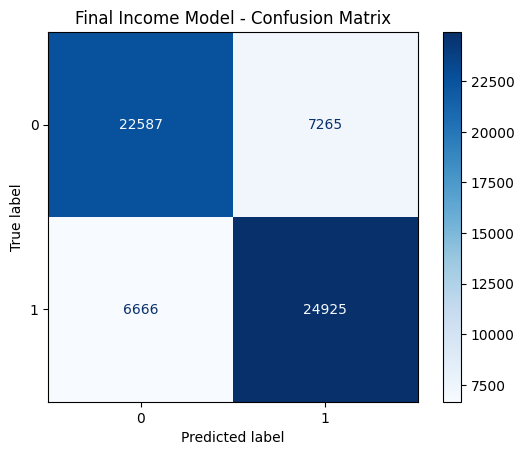

In [301]:
# Choose the final income target and features.
final_target = "INCOME_50K"
final_features = all_features

X = cleaned_dataset[final_features].copy()
y = cleaned_dataset[final_target]

# Convert categorical predictors.
for col in cat_cols:
    if col in X.columns:
        X[col] = X[col].astype("Int64").astype("category")

# Combine training and validation respondents for final fitting.
fit_rows = np.concatenate([train_rows, val_rows])
X_train_final = X.iloc[fit_rows]
y_train_final = y.iloc[fit_rows]
X_test_final = X.iloc[test_rows]
y_test_final = y.iloc[test_rows]

# Train the final model with the selected settings.
final_model = HistGradientBoostingClassifier(
    learning_rate=0.05,
    max_iter=400,
    max_leaf_nodes=31,
    min_samples_leaf=30,
    l2_regularization=0.5,
    categorical_features="from_dtype",
    early_stopping=True,
    random_state=42
)
final_model.fit(X_train_final, y_train_final)

# Evaluate once on the reserved test data.
final_predictions = final_model.predict(X_test_final)
print("Final test accuracy:", round(accuracy_score(y_test_final, final_predictions), 4))
print("Final test macro F1:", round(f1_score(y_test_final, final_predictions, average="macro"), 4))
print(classification_report(y_test_final, final_predictions, zero_division=0))

# ROC-AUC is used for binary income targets only.
if y.nunique() == 2:
    final_probabilities = final_model.predict_proba(X_test_final)[:, 1]
    print("Final ROC-AUC:", round(roc_auc_score(y_test_final, final_probabilities), 4))

# Show which income groups were predicted correctly or incorrectly.
ConfusionMatrixDisplay.from_predictions(y_test_final, final_predictions, cmap="Blues")
plt.title("Final Income Model - Confusion Matrix")
plt.show()


## **Conclusion**

**Final model.** Gradient Boosting predicting whether a household earns $50k or more reached 77.3% accuracy and a ROC-AUC of 0.858 on the test rows, which were used only once. Always guessing the larger group would score about 51%.

**Does activity matter?** It does when little else is known. With only age and sex, adding the activity columns raises AUC from 0.620 to 0.693. Once education, employment, marital status, and health are included, the gain shrinks to roughly 0.001 to 0.004, and it is similar for working-age adults and across age groups. In practice, activity tells the model very little that education, employment, and marital status do not already tell it.

**Limits to keep in mind**
- Income is household income in brackets, and the top bracket ($75k+) holds 35% of respondents.
- The results use the unweighted sample, so they describe these respondents, not the US population.
- This is an association, not a cause. Activity is self-reported.
- Race was not used as a predictor. [Add your reason here.]
- Gains of about 0.002 AUC are small enough to move from run to run, so differences between individual age groups should not be over-read. Confidence ranges were not calculated.
